# 03 · Value surfaces V(s)
Bake-off results, chosen specification, and rink heatmaps.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
import polars as pl, numpy as np
import matplotlib.pyplot as plt
from src.config import load_config
cfg = load_config()
proc = cfg.path(cfg.data.processed_dir)
pl.Config.set_tbl_rows(25); pl.Config.set_tbl_width_chars(160)

polars.config.Config

In [2]:
vb = json.load(open(cfg.path(cfg.data.metrics_dir) / 'value_bakeoff.json'))
print('chosen:', vb['chosen'])
pl.DataFrame([{k: v for k, v in r.items()} for r in vb['bakeoff']['rows']]).select('spec','mse','r2_vs_const','calib_slope','d_mse_vs_best','se_d_mse','tied_with_best').sort('mse')

chosen: gbm/cont/score


spec,mse,r2_vs_const,calib_slope,d_mse_vs_best,se_d_mse,tied_with_best
str,f64,f64,f64,f64,f64,bool
"""gbm/cont/score""",0.002912,0.204418,0.960905,0.0,0.0,true
"""mc/zones/k=auto/score""",0.002914,0.203752,0.955677,0.000002,8.6753e-7,false
"""mc/grid10/k=auto/score""",0.002915,0.203472,0.956747,0.000003,8.6829e-7,false
"""gbm/cont""",0.002921,0.201755,0.958086,0.00001,9.7642e-7,false
"""mc/grid10/k=200""",0.002922,0.201567,0.956358,0.00001,0.000001,false
"""mc/grid10/k=50""",0.002922,0.201542,0.953049,0.000011,0.000001,false
"""mc/zones/k=50""",0.002922,0.201528,0.954717,0.000011,0.000001,false
"""mc/grid20/k=50""",0.002923,0.201463,0.953963,0.000011,0.000001,false
"""mc/zones/k=200""",0.002923,0.201458,0.956663,0.000011,0.000001,false


In [3]:
v5 = pl.read_parquet(cfg.path(cfg.data.value_dir) / 'v_state_5v5.parquet')
v5.filter(pl.col('kind') == 'control').sort('v', descending=True).head(15)

state_id,sgroup,kind,spatial,n,v_raw,v_parent,v
str,str,str,str,i64,f64,f64,f64
"""5v5|control|17_4""","""5v5""","""control""","""17_4""",178,0.068156,0.053084,0.059007
"""5v5|control|18_4""","""5v5""","""control""","""18_4""",101,0.057632,0.053084,0.054306
"""5v5|control|18_5""","""5v5""","""control""","""18_5""",93,0.053226,0.053084,0.05312
"""5v5|control|17_5""","""5v5""","""control""","""17_5""",229,0.050348,0.053084,0.05184
"""5v5|control|17_6""","""5v5""","""control""","""17_6""",191,0.0433,0.053084,0.049073
"""5v5|control|16_5""","""5v5""","""control""","""16_5""",254,0.050506,0.044368,0.047316
"""5v5|control|16_4""","""5v5""","""control""","""16_4""",214,0.039146,0.044368,0.042082
"""5v5|control|15_6""","""5v5""","""control""","""15_6""",194,0.031474,0.044368,0.039034
"""5v5|control|18_3""","""5v5""","""control""","""18_3""",290,0.043788,0.032353,0.038223


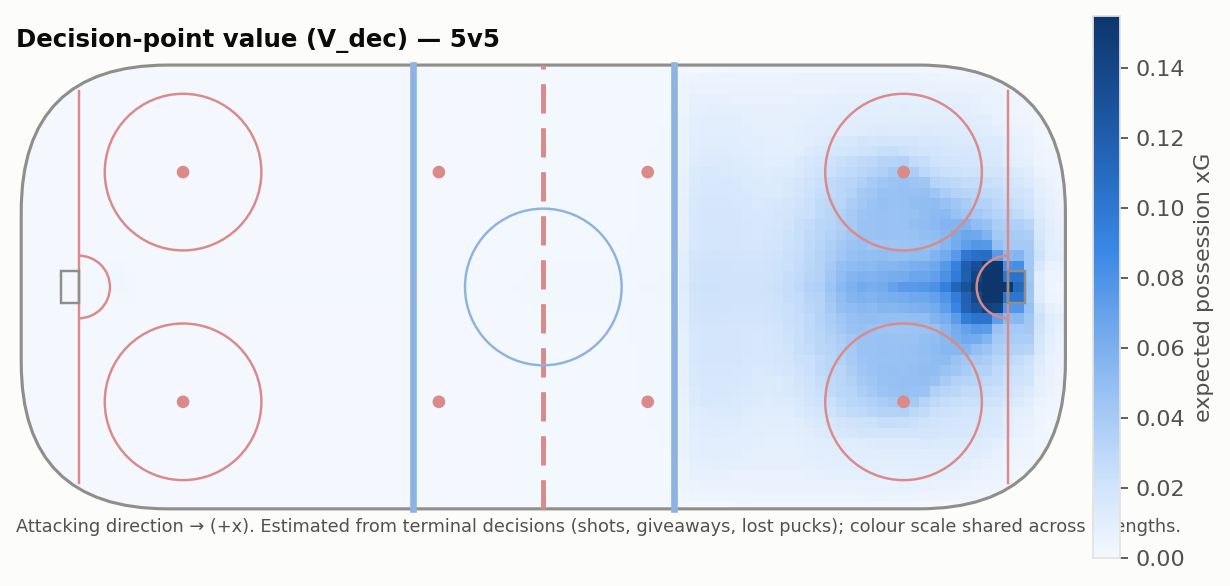

In [4]:
from IPython.display import Image
Image(str(cfg.path(cfg.data.figures_dir) / 'value_surfaces' / 'v_dec_5v5_full.png'))

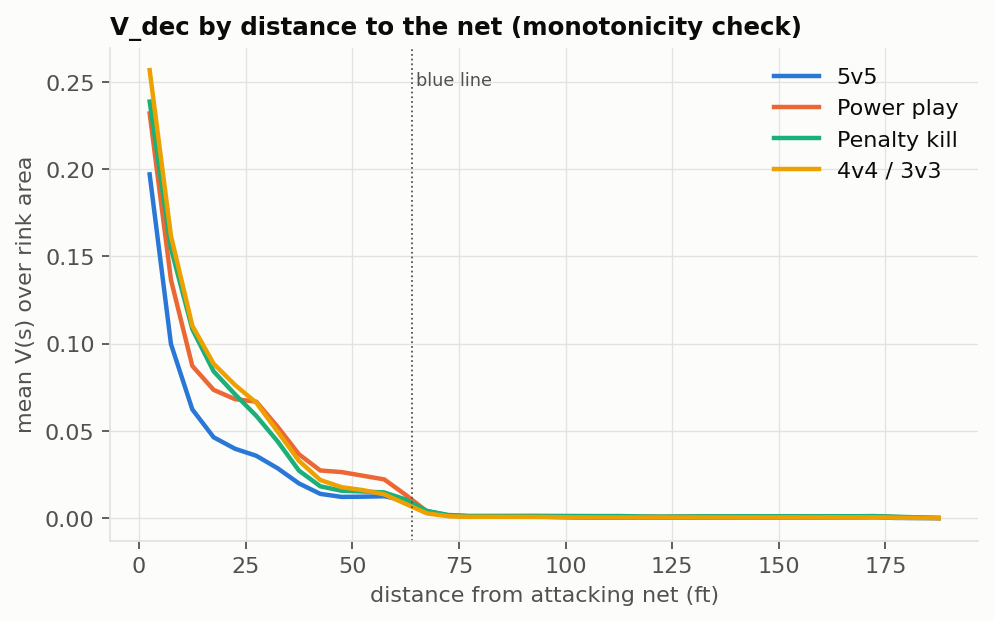

In [5]:
Image(str(cfg.path(cfg.data.figures_dir) / 'value_surfaces' / 'v_dec_by_distance.png'))